# Tema 3, Exercițiul 2
## Diagnostic boală pulmonară

Variabile binare: boala pulmonară $B$, tuse $T$, dificultate de respirație $D$, radiografie anormală $X$.

Dependențe:
- $B$ influențează $T$, $X$ și $D$;
- $D$ depinde atât de $B$, cât și de $T$.

$$B \rightarrow T, \qquad B \rightarrow X, \qquad B \rightarrow D, \qquad T \rightarrow D$$

$$P(B, T, X, D) = P(B)\,P(T \mid B)\,P(X \mid B)\,P(D \mid B, T)$$

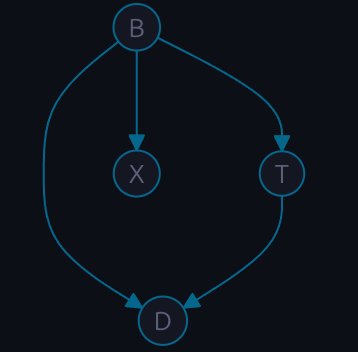

Probabilitățile din enunț:

$$P(B{=}1)=0.1$$
$$P(T{=}1\mid B{=}1)=0.8,\quad P(T{=}1\mid B{=}0)=0.3$$
$$P(X{=}1\mid B{=}1)=0.9,\quad P(X{=}1\mid B{=}0)=0.1$$
$$P(D{=}1\mid B{=}1,T{=}1)=0.9,\quad P(D{=}1\mid B{=}1,T{=}0)=0.4$$
$$P(D{=}1\mid B{=}0,T{=}1)=0.5,\quad P(D{=}1\mid B{=}0,T{=}0)=0.1$$

## a) Modelul probabilist în pgmpy

Definim întâi structura rețelei (arcele dintre variabile).

In [ ]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

model = DiscreteBayesianNetwork([("B", "T"), ("B", "X"), ("B", "D"), ("T", "D")])

/home/stefan/Laboratoare/PMP/PMP-2026/.venv/lib/python3.12/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Apoi definim tabelele de probabilitate condiționată (CPD). În fiecare `TabularCPD`, un rând = o valoare a variabilei, iar o coloană = o combinație de valori ale părinților (fiecare coloană însumează 1).

In [ ]:
# B nu are parinti -> o singura coloana (probabilitatea apriori)
cpd_B = TabularCPD("B", 2,
    [[0.9],   # P(B=0)
     [0.1]])  # P(B=1)

# Coloane dupa B: B=0 B=1
cpd_T = TabularCPD("T", 2,
    [[0.7, 0.2],   # P(T=0 | B=0),  P(T=0 | B=1)
     [0.3, 0.8]],  # P(T=1 | B=0),  P(T=1 | B=1)
    evidence=["B"], evidence_card=[2])

# Coloane dupa B: B=0 B=1
cpd_X = TabularCPD("X", 2,
    [[0.9, 0.1],   # P(X=0 | B=0),  P(X=0 | B=1)
     [0.1, 0.9]],  # P(X=1 | B=0),  P(X=1 | B=1)
    evidence=["B"], evidence_card=[2])

# Coloane dupa (B, T)
# B=0,T=0   B=0,T=1   B=1,T=0   B=1,T=1
cpd_D = TabularCPD("D", 2,
    [[0.9, 0.5, 0.6, 0.1],   # P(D=0 | B, T)
     [0.1, 0.5, 0.4, 0.9]],  # P(D=1 | B, T)
    evidence=["B", "T"], evidence_card=[2, 2])

Atașăm CPD-urile la model și verificăm consistența.

In [ ]:
model.add_cpds(cpd_B, cpd_T, cpd_X, cpd_D)
print("model valid:", model.check_model())

model valid: True


## b) Pacientul are tuse și dificultate de respirație. $P(B \mid T=1, D=1)$?

In [ ]:
inf = VariableElimination(model)
q = inf.query(["B"], evidence={"T": 1, "D": 1}, show_progress=False)
print(q)

+------+----------+
| B    |   phi(B) |
+======+==========+
| B(0) |   0.6522 |
+------+----------+
| B(1) |   0.3478 |
+------+----------+


Rezultat: $P(B=1 \mid T=1, D=1) \approx 0.3478$.

## c) Se știe că pacientul **nu** avea boala. $P(X=1 \mid B=0)$?

In [ ]:
q2 = inf.query(["X"], evidence={"B": 0}, show_progress=False)
print(q2)

+------+----------+
| X    |   phi(X) |
+======+==========+
| X(0) |   0.9000 |
+------+----------+
| X(1) |   0.1000 |
+------+----------+


Rezultat: $P(X=1 \mid B=0) = 0.1$, exact valoarea din tabel, $X$ depinde doar de $B$, deci condiționarea pe $B=0$ dă direct $P(X=1 \mid B=0)$.

## d) Calculul cu regula lui Bayes

### b) $P(B \mid T=1, D=1)$

Regula lui Bayes: $P(B \mid T{=}1, D{=}1) = \dfrac{P(B, T{=}1, D{=}1)}{P(T{=}1, D{=}1)}$.

Pornim de la $P(B, T, X, D) = P(B)\,P(T \mid B)\,P(X \mid B)\,P(D \mid B, T)$. 

Deoarece $X$ este o frunză care depinde doar de $B$, suma $\sum_X P(X \mid B) = 1$.

$$P(B, T{=}1, D{=}1) = P(B)\,P(T{=}1 \mid B)\,P(D{=}1 \mid B, T{=}1)$$

Evaluăm această expresie pentru fiecare valoare a lui $B$, înlocuind fiecare factor cu valoarea din tabel:

$$P(B{=}1, T{=}1, D{=}1) = \underbrace{0.1}_{P(B=1)} \cdot \underbrace{0.8}_{P(T=1\mid B=1)} \cdot \underbrace{0.9}_{P(D=1\mid B=1,T=1)} = 0.072$$

$$P(B{=}0, T{=}1, D{=}1) = \underbrace{0.9}_{P(B=0)} \cdot \underbrace{0.3}_{P(T=1\mid B=0)} \cdot \underbrace{0.5}_{P(D=1\mid B=0,T=1)} = 0.135$$

$$P(B{=}1 \mid T{=}1, D{=}1) = \frac{P(B{=}1, T{=}1, D{=}1)}{\underbrace{P(B{=}0, T{=}1, D{=}1) + P(B{=}1, T{=}1, D{=}1)}_{P(T{=}1,\, D{=}1)}}$$

$$P(B{=}1 \mid T{=}1, D{=}1) = \frac{0.072}{0.135 + 0.072} = \frac{0.072}{0.207} = \frac{8}{23} \approx 0.3478$$

### c) $P(X=1 \mid B=0)$

În rețea $X$ depinde doar de $B$.

$$P(X{=}1 \mid B{=}0) = 0.1$$